In [2]:
# Run in conda ibiz environment
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import os

from preprocess_radargrams_configs import AMPLITUDE_VMIN, AMPLITUDE_VMAX, COLOR_MAP
from preprocess_radargrams_configs import TX_OFFSET_EAGLE_HiCARS2_microseconds, TX_OFFSET_IceBridge_HiCARS1_microseconds, TX_OFFSET_IceBridge_HiCARS2_microseconds

from utils import load_L1B_radargram, get_l2_path_from_l1b, load_l2_ice_thickness, add_polarstereo_coordinates, merge_radargram_and_l1b, convert_radargram_to_elevations
from utils import generate_bed_idx_and_mask, crop_tiles_extract_metadata


# IceBridge HiCARS 1
from paths import path_to_IR1HI1B, path_to_IR1HI2_ice_thickness
# IceBridge HiCARS 2
from paths import path_to_IR2HI1B, path_to_IR2HI2_ice_thickness

# IceBridge HiCARS1

In [24]:
list_of_nc_files_IceBridge_HiCARS1_full_paths = sorted(
    os.path.join(path_to_IR1HI1B, f)
    for f in os.listdir(path_to_IR1HI1B)
    if f.endswith(".nc")
)

print(len(list_of_nc_files_IceBridge_HiCARS1_full_paths), "files found.")

1152 files found.


In [25]:
# Store as list first, then convert to torch tensor and pandas dataframe after the loop
all_tiles, all_meta = [], []

skipped = []

n_granules = len(list_of_nc_files_IceBridge_HiCARS1_full_paths)

for i, path_to_l1b_granule in enumerate(list_of_nc_files_IceBridge_HiCARS1_full_paths, start = 0):
    # Keep track of progress through radargrams
    print(f"Granule {i} / {n_granules}")
    
    # 1. Load radargram and crop if lat/lon are missing
    radargram_ds = load_L1B_radargram(path_to_l1b_granule)
    # Continue to next granule if, for instance, no valid lat/lon coordinates are found.
    if radargram_ds is None:
        print("------------------------------")
        continue

    # 2. Get the corresponding L2 file path
    path_to_l2_file = get_l2_path_from_l1b(radargram_ds.granule_id, path_to_IR1HI2_ice_thickness)

    # 3. Load L2 data
    l2_df = load_l2_ice_thickness(path_to_l2_file)

    if l2_df is None:
        skipped.append((str(radargram_ds.granule_id), "no L2 file or no valid rows"))
        print("------------------------------")
        continue

    # 4. Add Antarctic Polar Stereographic coordinates to L2 dataframe
    l2_df = add_polarstereo_coordinates(l2_df)

    # 5. Add l2 data to l1b
    radargram_ds_l2 = merge_radargram_and_l1b(radargram_ds, l2_df) 

    # 6. Convert radargram to elevations (2D grid of absolute elevations above sea level, in meters)
    # NOTE: Input the correct TX_OFFSET for the radargram type (HiCARS 1 or HiCARS 2) to convert fasttime to TWTT correctly.
    elevations_m = convert_radargram_to_elevations(radargram_ds_l2, TX_OFFSET_IceBridge_HiCARS1_microseconds)

    # 7. Generate bed index and mask
    bed_idx, bed_mask = generate_bed_idx_and_mask(elevations_m, radargram_ds_l2)

    # 8. Crop tiles for one radargram 
    tiles_per_granule, metadata_per_granule = crop_tiles_extract_metadata(radargram_ds_l2, elevations_m, bed_idx)

    if tiles_per_granule is None:
        print("------------------------------")
        continue

    all_tiles.append(tiles_per_granule)
    all_meta.append(metadata_per_granule)

    break

# after the loop, once all the data is collected
# list to numpy array and pandas dataframe
tiles_np = np.concatenate(all_tiles, axis = 0)
tiles_metadata = pd.concat(all_meta, ignore_index = True)
# make tensor  
tiles_tensor = torch.from_numpy(tiles_np).unsqueeze(1) 
print(skipped)

Granule 0 / 1152
Now processing Granule ID: IR1HI1B_2009002_MCM_JKB1a_BYRD03a_000
L1B radargram shape (rows, columns): (3200, 4000)
L1B radargram number of columns missing LON, LAT or BOTH: 79
------------------------------
Granule 1 / 1152
Now processing Granule ID: IR1HI1B_2009002_MCM_JKB1a_BYRD03a_001
L1B radargram shape (rows, columns): (3200, 4000)
L1B radargram number of columns missing LON, LAT or BOTH: 0
------------------------------
Granule 2 / 1152
Now processing Granule ID: IR1HI1B_2009002_MCM_JKB1a_BYRD03a_002
L1B radargram shape (rows, columns): (3200, 334)
L1B radargram number of columns missing LON, LAT or BOTH: 0
------------------------------
Granule 3 / 1152
Now processing Granule ID: IR1HI1B_2009002_MCM_JKB1a_BYRD03b_001
L1B radargram shape (rows, columns): (3200, 4000)
L1B radargram number of columns missing LON, LAT or BOTH: 2808
------------------------------
Granule 4 / 1152
Now processing Granule ID: IR1HI1B_2009002_MCM_JKB1a_BYRD03b_002
L1B radargram shape (ro

KeyError: 'SRF_REFLECT'

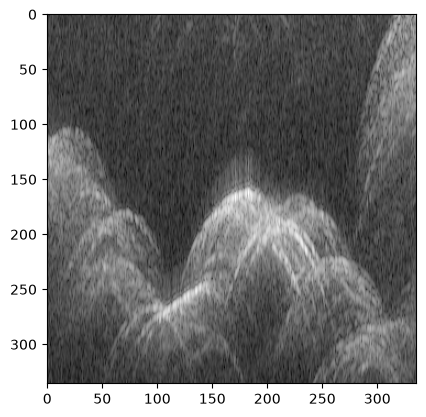

In [31]:
tiles_per_granule[0, :, :]
plt.imshow(tiles_per_granule[0, :, :], cmap = "gray")

In [5]:
print(*skipped, sep = "\n")

('IR1HI1B_2009002_MCM_JKB1a_BYRD03a_001', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_BYRD03a_002', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_BYRD03b_002', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_DGC02a_000', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_DGC02a_001', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_DGT02a_000', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_DGT02a_001', 'no L2 file or no valid rows')
('IR1HI1B_2009002_MCM_JKB1a_DGT03a_000', 'no L2 file or no valid rows')
('IR1HI1B_2009006_MCM_JKB1a_EDMC01a_001', 'no L2 file or no valid rows')
('IR1HI1B_2009006_MCM_JKB1a_WLKX01a_000', 'no L2 file or no valid rows')
('IR1HI1B_2009006_MCM_JKB1a_WLKX01a_001', 'no L2 file or no valid rows')
('IR1HI1B_2009006_MCM_JKB1a_WLKX01a_002', 'no L2 file or no valid rows')
('IR1HI1B_2009006_MCM_JKB1a_WLKX01a_003', 'no L2 file or no valid rows')
('IR1HI1B_2009006_MCM_JKB1a_WLKX01a_004', 'no L2 file or

In [ ]:
torch.save(tiles_tensor, "data/tiles_tensor_IceBridge_HiCARS1.pt")
pd.DataFrame.to_csv(tiles_metadata, "data/tiles_metadata_IceBridge_HiCARS1.csv", index = False)

In [10]:
tiles_np.shape

(3795, 336, 336)

In [10]:
start = 3000
n = 2
for i in range(start, start + n):
    plt.imshow(tiles_tensor[i, :, :, :].mean(dim = 0).numpy(), cmap = "gray")
    plt.show()

NameError: name 'tiles_tensor' is not defined

# IceBridge HiCARS2

In [12]:
list_of_nc_files_IceBridge_HiCARS2_full_paths = sorted(
    os.path.join(path_to_IR2HI1B, f)
    for f in os.listdir(path_to_IR2HI1B)
    if f.endswith(".nc")
)

print(len(list_of_nc_files_IceBridge_HiCARS2_full_paths), "files found.")

1076 files found.


In [13]:
# Store as list first, then convert to torch tensor and pandas dataframe after the loop
all_tiles, all_meta = [], []

skipped = []

n_granules = len(list_of_nc_files_IceBridge_HiCARS2_full_paths)

for i, path_to_l1b_granule in enumerate(list_of_nc_files_IceBridge_HiCARS2_full_paths, start = 0):
    # Keep track of progress through radargrams
    print(f"Granule {i} / {n_granules}")
    
    # 1. Load radargram and crop if lat/lon are missing
    radargram_ds = load_L1B_radargram(path_to_l1b_granule)
    # Continue to next granule if, for instance, no valid lat/lon coordinates are found.
    if radargram_ds is None:
        print("------------------------------")
        continue

    # 2. Get the corresponding L2 file path
    path_to_l2_file = get_l2_path_from_l1b(radargram_ds.granule_id, path_to_IR2HI2_ice_thickness)

    # 3. Load L2 data
    l2_df = load_l2_ice_thickness(path_to_l2_file)

    if l2_df is None:
        skipped.append((str(radargram_ds.granule_id), "no L2 file or no valid rows"))
        print("------------------------------")
        continue

    # 4. Add Antarctic Polar Stereographic coordinates to L2 dataframe
    l2_df = add_polarstereo_coordinates(l2_df)

    # 5. Add l2 data to l1b
    radargram_ds_l2 = merge_radargram_and_l1b(radargram_ds, l2_df) 

    # 6. Convert radargram to elevations (2D grid of absolute elevations above sea level, in meters)
    # NOTE: Input the correct TX_OFFSET for the radargram type (HiCARS 1 or HiCARS 2) to convert fasttime to TWTT correctly.
    elevations_m = convert_radargram_to_elevations(radargram_ds_l2, TX_OFFSET_IceBridge_HiCARS2_microseconds)

    # 7. Generate bed index and mask
    bed_idx, bed_mask = generate_bed_idx_and_mask(elevations_m, radargram_ds_l2)

    # 8. Crop tiles for one radargram 
    tiles_per_granule, metadata_per_granule = crop_tiles_extract_metadata(radargram_ds_l2, elevations_m, bed_idx)

    if tiles_per_granule is None:
        print("------------------------------")
        continue

    all_tiles.append(tiles_per_granule)
    all_meta.append(metadata_per_granule)

    # break

# after the loop, once all the data is collected
# list to numpy array and pandas dataframe
tiles_np = np.concatenate(all_tiles, axis = 0)
tiles_metadata = pd.concat(all_meta, ignore_index = True)
# make tensor  
tiles_tensor = torch.from_numpy(tiles_np).unsqueeze(1) 
print(skipped)

Granule 0 / 1076
Now processing Granule ID: IR2HI1B_2010340_ICP3_JKB2c_F25T01b_000
L1B radargram shape (rows, columns): (3200, 4000)
L1B radargram number of columns missing LON, LAT or BOTH: 0
L2 shape (rows): 5337
L2 number of columns missing LON, LAT or BOTH: 7
Matched: 4000 / 4000
------------------------------
Granule 1 / 1076
Now processing Granule ID: IR2HI1B_2010340_ICP3_JKB2c_F25T01b_001
L1B radargram shape (rows, columns): (3200, 1341)
L1B radargram number of columns missing LON, LAT or BOTH: 9
INFO: Cropped 9 trailing columns with missing LON/LAT
L2 shape (rows): 5337
L2 number of columns missing LON, LAT or BOTH: 7
Matched: 1332 / 1332
------------------------------
Granule 2 / 1076
Now processing Granule ID: IR2HI1B_2010340_WSB_JKB2c_GL1325c_000
L1B radargram shape (rows, columns): (3200, 4000)
L1B radargram number of columns missing LON, LAT or BOTH: 0
------------------------------
Granule 3 / 1076
Now processing Granule ID: IR2HI1B_2010340_WSB_JKB2c_GL1325c_001
L1B radar

### Missing thickness files

Indeed it appears that a fair few radargrams are missing their corresponding thickness files.

One of the 41 granules missing a thickness file is: IR2HI1B_2010340_WSB_JKB2c_GL1325c_000
The only thickness file from this date is: IR2HI2_2010340_ICP3_JKB2c_F25T01b_icethk.txt

Search: 
https://search.earthdata.nasa.gov/search/granules?p=C3204981465-NSIDC_CPRD&pg[0][v]=f&pg[0][id]=*_2010340_*&pg[0][gsk]=-start_date&q=hicars
search for instance *_2010340_*

In [20]:
print(len(skipped), "granules skipped:")
skipped

41 granules skipped:


[('IR2HI1B_2010340_WSB_JKB2c_GL1325c_000', 'no L2 file or no valid rows'),
 ('IR2HI1B_2010340_WSB_JKB2c_GL1325c_001', 'no L2 file or no valid rows'),
 ('IR2HI1B_2010340_WSB_JKB2c_GL1325c_002', 'no L2 file or no valid rows'),
 ('IR2HI1B_2010340_WSB_JKB2c_GL1325c_003', 'no L2 file or no valid rows'),
 ('IR2HI1B_2010340_WSB_JKB2c_R35a_000', 'no L2 file or no valid rows'),
 ('IR2HI1B_2010340_WSB_JKB2c_R35a_001', 'no L2 file or no valid rows'),
 ('IR2HI1B_2010340_WSB_JKB2c_R35a_002', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011007_ICP3_JKB2d_F42T01a_000', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011314_ICP4_JKB2e_MULK02a_000', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011318_WSB_JKB2f_GL0283c_000', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011318_WSB_JKB2f_GL0283c_001', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011334_ICP4_JKB2e_F11T02a_000', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011334_ICP4_JKB2e_F11T02a_001', 'no L2 file or no valid rows'),
 ('IR2HI1B_2011334_ICP4_JKB2e_

## Save tensor and metadata

In [14]:
torch.save(tiles_tensor, "data/tiles_tensor_IceBridge_HiCARS2.pt")
pd.DataFrame.to_csv(tiles_metadata, "data/tiles_metadata_IceBridge_HiCARS2.csv", index = False)

## Visualise some times

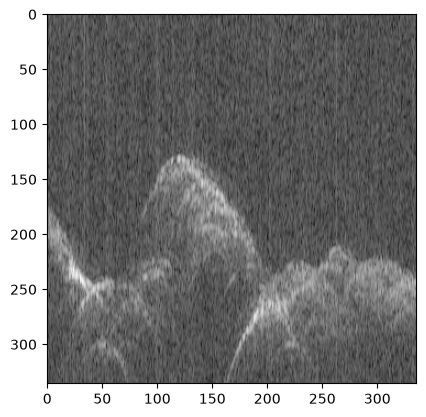

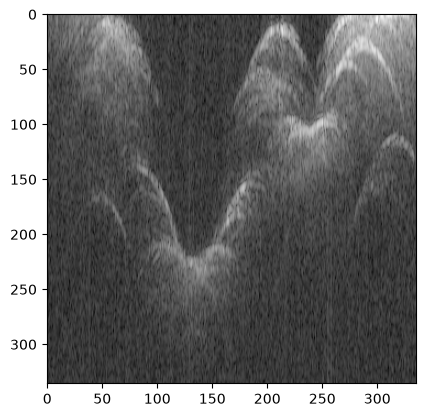

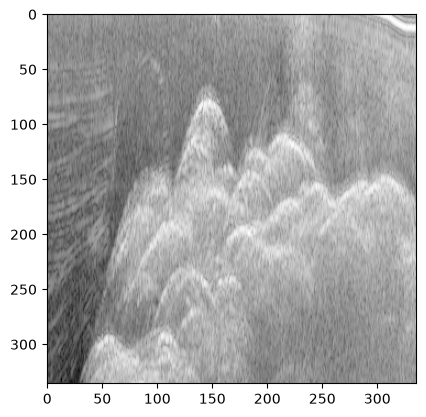

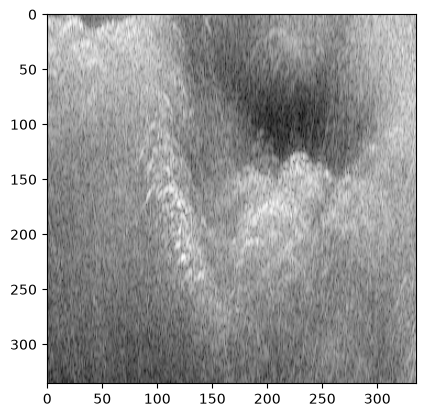

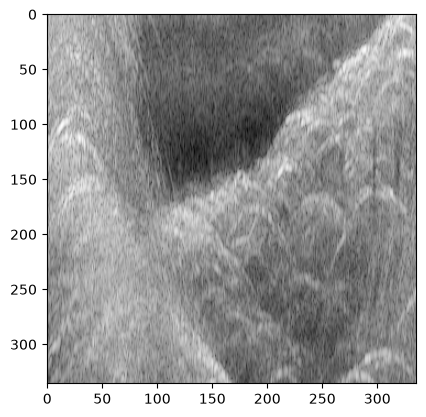

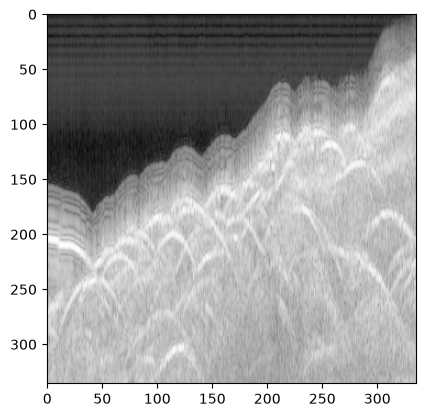

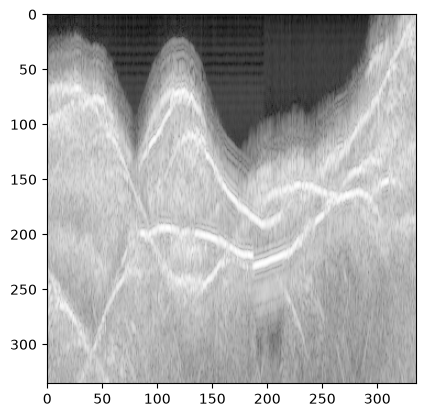

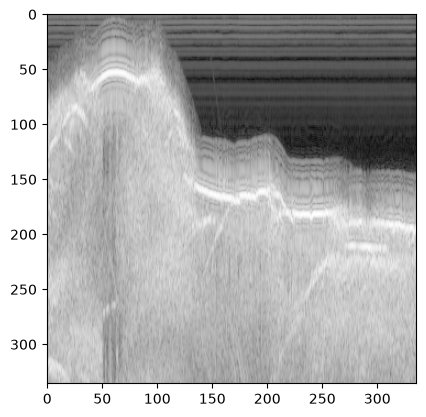

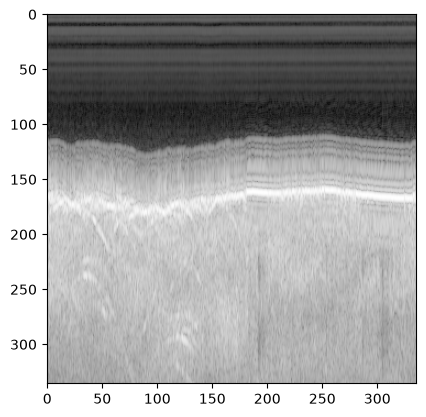

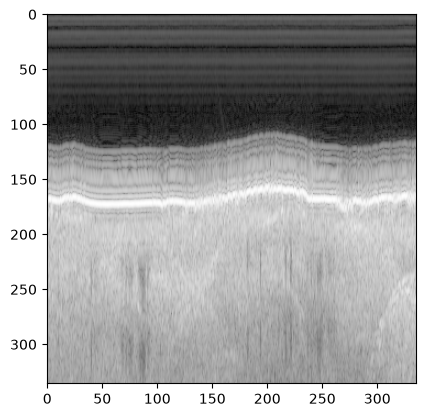

In [16]:
start = 3000
n = 10
for i in range(start, start + n):
    plt.imshow(tiles_tensor[i, :, :, :].mean(dim = 0).numpy(), cmap = "gray")
    plt.show()